In [3]:
import pandas as pd 
df = pd.read_csv("..//static//csv//Forbes Billionaires.csv")
print(df.columns)

Index(['Rank ', 'Name', 'Networth', 'Age', 'Country', 'Source', 'Industry'], dtype='object')


Выбрать входные и выходные переменные.

##### Входные переменные: 
- Age (Возраст)
- Country (Страна)
##### Выходная переменная:
- Networth (Чистый доход)

Выполнить настройку параметров лингвистических переменных: определить
количество термов, типов и параметров функций принадлежности.

Для переменной Networth
- Термы: Низкий, Средний, Высокий
- Тип функции принадлежности: Треугольная
- Параметры:
- Низкий: (0, 100, 200)
- Средний: (150, 300, 500)
- Высокий: (400, 800, 1000)

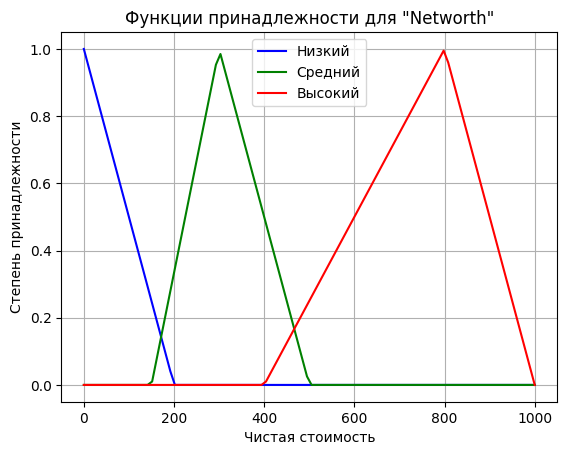

In [13]:
# Определение диапазона значений для переменной "Networth"
x_networth = np.linspace(0, 1000, 100)

# Определение функций принадлежности для термов
# Низкий
low = fuzz.trimf(x_networth, [0, 0, 200])
# Средний
medium = fuzz.trimf(x_networth, [150, 300, 500])
# Высокий
high = fuzz.trimf(x_networth, [400, 800, 1000])

# Визуализация функций принадлежности
plt.figure()
plt.plot(x_networth, low, label='Низкий', color='blue')
plt.plot(x_networth, medium, label='Средний', color='green')
plt.plot(x_networth, high, label='Высокий', color='red')
plt.title('Функции принадлежности для "Networth"')
plt.xlabel('Чистая стоимость')
plt.ylabel('Степень принадлежности')
plt.legend()
plt.grid()
plt.show()

Сформировать базу нечетких правил.


Нечеткие правила:
Если Возраст Низкий И Страна Развивающаяся, Тогда Чистая стоимость Низкая.
Если Возраст Средний И Страна Развивающаяся, Тогда Чистая стоимость Средняя.
Если Возраст Высокий И Страна Развита, Тогда Чистая стоимость Высокая.
Если Возраст Низкий И Страна Развита, Тогда Чистая стоимость Средняя.
Если Возраст Средний И Страна Развита, Тогда Чистая стоимость Высокая.


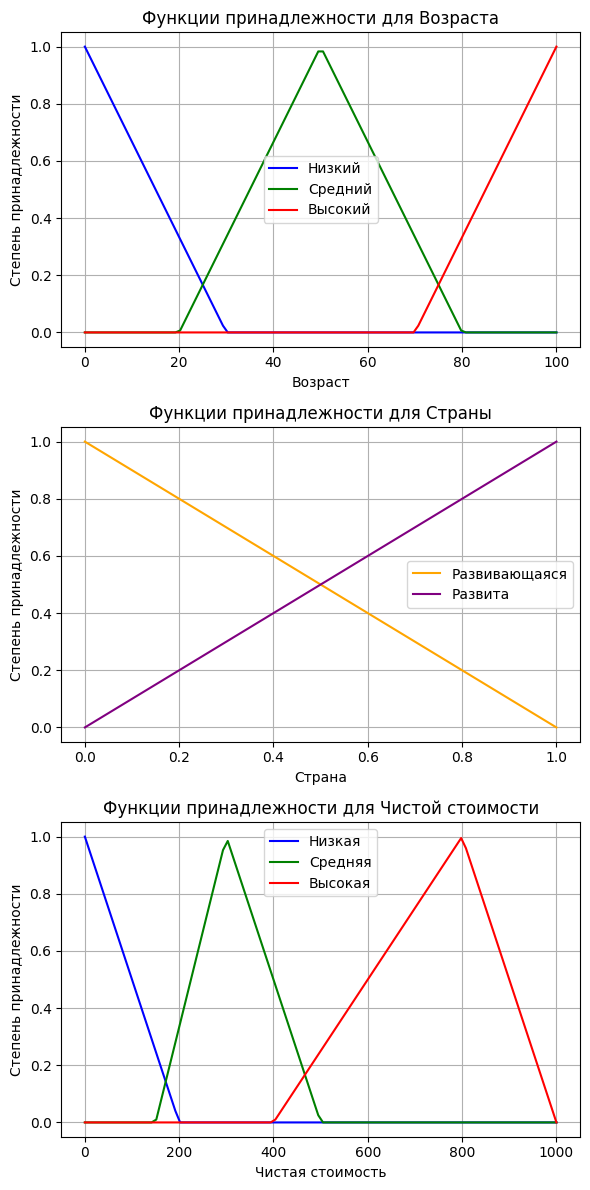

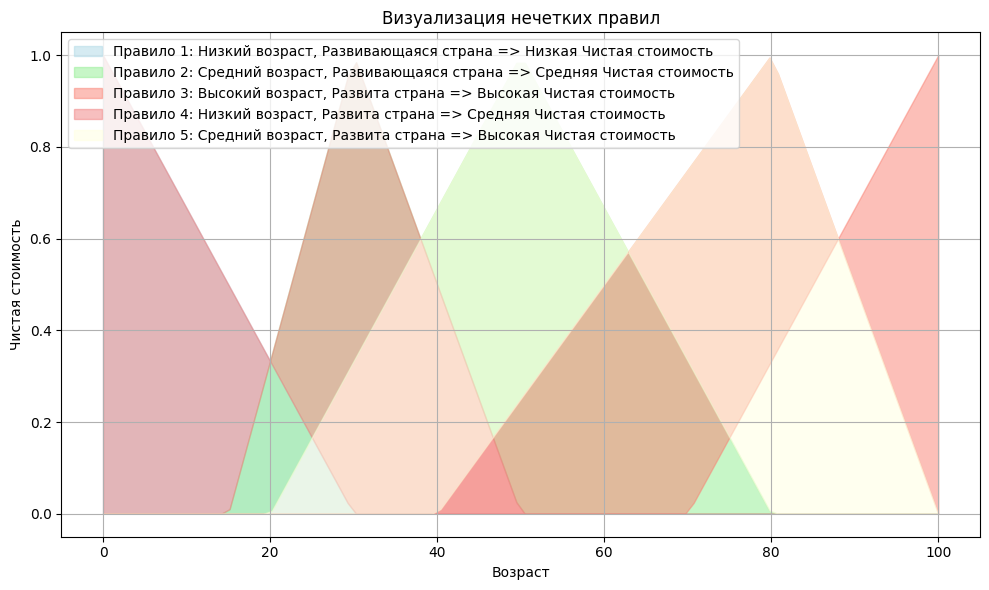

In [24]:
import numpy as np
import skfuzzy as fuzz
import matplotlib.pyplot as plt

#правила определают как связаны входные (возраст и страна) и выходные (Чистый доход) переменные

# Определение диапазонов значений для входных переменных
x_age = np.linspace(0, 100, 100)  # Возраст
x_country = np.array([0, 1])  # 0 - Развивающаяся, 1 - Развита
x_networth = np.linspace(0, 1000, 100)  # Чистая стоимость

# Определение функций принадлежности для возраста
low_age = fuzz.trimf(x_age, [0, 0, 30])
medium_age = fuzz.trimf(x_age, [20, 50, 80])
high_age = fuzz.trimf(x_age, [70, 100, 100])

# Определение функций принадлежности для страны
developing = fuzz.trimf(x_country, [0, 0, 1])  # Развивающаяся
developed = fuzz.trimf(x_country, [0, 1, 1])  # Развита

# Определение функций принадлежности для чистой стоимости
low_networth = fuzz.trimf(x_networth, [0, 0, 200])
medium_networth = fuzz.trimf(x_networth, [150, 300, 500])
high_networth = fuzz.trimf(x_networth, [400, 800, 1000])

# Определение нечетких правил
fuzzy_rules = [
    ("Низкий", "Развивающаяся", "Низкая"),
    ("Средний", "Развивающаяся", "Средняя"),
    ("Высокий", "Развита", "Высокая"),
    ("Низкий", "Развита", "Средняя"),
    ("Средний", "Развита", "Высокая")
]

# Вывод правил
print("Нечеткие правила:")
for rule in fuzzy_rules:
    print(f"Если Возраст {rule[0]} И Страна {rule[1]}, Тогда Чистая стоимость {rule[2]}.")

# Визуализация функций принадлежности
fig, axs = plt.subplots(3, 1, figsize=(6, 12))

# Возраст
axs[0].plot(x_age, low_age, label='Низкий', color='blue')
axs[0].plot(x_age, medium_age, label='Средний', color='green')
axs[0].plot(x_age, high_age, label='Высокий', color='red')
axs[0].set_title('Функции принадлежности для Возраста')
axs[0].set_xlabel('Возраст')
axs[0].set_ylabel('Степень принадлежности')
axs[0].legend()
axs[0].grid()

# Страна
axs[1].plot(x_country, developing, label='Развивающаяся', color='orange')
axs[1].plot(x_country, developed, label='Развита', color='purple')
axs[1].set_title('Функции принадлежности для Страны')
axs[1].set_xlabel('Страна')
axs[1].set_ylabel('Степень принадлежности')
axs[1].legend()
axs[1].grid()

# Чистая стоимость
axs[2].plot(x_networth, low_networth, label='Низкая', color='blue')
axs[2].plot(x_networth, medium_networth, label='Средняя', color='green')
axs[2].plot(x_networth, high_networth, label='Высокая', color='red')
axs[2].set_title('Функции принадлежности для Чистой стоимости')
axs[2].set_xlabel('Чистая стоимость')
axs[2].set_ylabel('Степень принадлежности')
axs[2].legend()
axs[2].grid()

plt.tight_layout()
plt.show()

# Визуализация нечетких правил
fig, ax = plt.subplots(figsize=(10, 6))

# Заполнение областей для каждого правила
ax.fill_between(x_age, low_age, 0, color='lightblue', alpha=0.5, label='Правило 1: Низкий возраст, Развивающаяся страна => Низкая Чистая стоимость')
ax.fill_between(x_age, medium_age, medium_networth, color='lightgreen', alpha=0.5, label='Правило 2: Средний возраст, Развивающаяся страна => Средняя Чистая стоимость')
ax.fill_between(x_age, high_age, high_networth, color='salmon', alpha=0.5, label='Правило 3: Высокий возраст, Развита страна => Высокая Чистая стоимость')
ax.fill_between(x_age, low_age, medium_networth, color='lightcoral', alpha=0.5, label='Правило 4: Низкий возраст, Развита страна => Средняя Чистая стоимость')
ax.fill_between(x_age, medium_age, high_networth, color='lightyellow', alpha=0.5, label='Правило 5: Средний возраст, Развита страна => Высокая Чистая стоимость')

ax.set_title('Визуализация нечетких правил')
ax.set_xlabel('Возраст')
ax.set_ylabel('Чистая стоимость')
ax.legend()
ax.grid()

plt.tight_layout()
plt.show()

Оценка качества полученной нечеткой системы.

In [26]:
import numpy as np
import skfuzzy as fuzz
import matplotlib.pyplot as plt

# Функции принадлежности (как ранее)
x_age = np.linspace(0, 100, 100)
x_country = np.array([0, 1])  # 0 - Развивающаяся, 1 - Развита
x_networth = np.linspace(0, 1000, 100)  # Чистая стоимость

# Определение функций принадлежности для возраста
low_age = fuzz.trimf(x_age, [0, 0, 30])
medium_age = fuzz.trimf(x_age, [20, 50, 80])
high_age = fuzz.trimf(x_age, [70, 100, 100])

# Определение функций принадлежности для чистой стоимости
low_networth = fuzz.trimf(x_networth, [0, 0, 200])
medium_networth = fuzz.trimf(x_networth, [150, 300, 500])
high_networth = fuzz.trimf(x_networth, [400, 800, 1000])

# Создаем тестовые данные (возраст, страна, эталонная чистая стоимость)
test_data = [
    (25, 0, 150),  # Низкий возраст, развивающаяся страна => Низкая чистая стоимость
    (35, 0, 300),  # Средний возраст, развивающаяся страна => Средняя чистая стоимость
    (75, 1, 800),  # Высокий возраст, развитая страна => Высокая чистая стоимость
    (50, 1, 600),  # Средний возраст, развитая страна => Средняя чистая стоимость
]

# Функция для вычисления нечеткой оценки
def fuzzy_inference(age, country):
    # Определение степени принадлежности
    age_low = fuzz.interp_membership(x_age, low_age, age)
    age_medium = fuzz.interp_membership(x_age, medium_age, age)
    age_high = fuzz.interp_membership(x_age, high_age, age)

    country_developing = fuzz.interp_membership(x_country, developing, country)
    country_developed = fuzz.interp_membership(x_country, developed, country)

    # Применяем правила
    networth_low = np.fmin(age_low, country_developing)
    networth_medium = np.fmin(age_medium, country_developing)
    networth_high = np.fmin(age_high, country_developed)

    # Вычисляем выходные значения при наличии ненулевых областей
    networth0 = low_networth * networth_low
    networth1 = medium_networth * networth_medium
    networth2 = high_networth * networth_high

    # Проверка на ненулевые области перед дефуззацией
    if networth_low > 0:
        networth0 = fuzz.defuzz(x_networth, networth0, 'centroid')
    else:
        networth0 = 0  # Значение по умолчанию

    if networth_medium > 0:
        networth1 = fuzz.defuzz(x_networth, networth1, 'centroid')
    else:
        networth1 = 0  # Значение по умолчанию

    if networth_high > 0:
        networth2 = fuzz.defuzz(x_networth, networth2, 'centroid')
    else:
        networth2 = 0  # Значение по умолчанию

    return max(networth0, networth1, networth2)

# Список для хранения результатов
results = []

# Оценка системы на тестовом наборе данных
for age, country, actual_networth in test_data:
    inferred_networth = fuzzy_inference(age, country)
    results.append((age, country, actual_networth, inferred_networth))

# Вывод результатов
print("Возраст | Страна | Эталонная чистая стоимость | Оцененная чистая стоимость")
for age, country, actual_networth, inferred_networth in results:
    print(f"{age:7} | {country:6} | {actual_networth:25} | {inferred_networth:.2f}")

# Вычисление метрик качества
actual_networths = [actual for _, _, actual, _ in results]
inferred_networths = [inferred for _, _, _, inferred in results]

mae = np.mean(np.abs(np.array(actual_networths) - np.array(inferred_networths)))
rmse = np.sqrt(np.mean((np.array(actual_networths) - np.array(inferred_networths)) ** 2))

print(f"\nСредняя абсолютная ошибка (MAE): {mae:.2f}")
print(f"Среднеквадратичная ошибка (RMSE): {rmse:.2f}")

Возраст | Страна | Эталонная чистая стоимость | Оцененная чистая стоимость
     25 |      0 |                       150 | 316.70
     35 |      0 |                       300 | 316.70
     75 |      1 |                       800 | 733.29
     50 |      1 |                       600 | 0.00

Средняя абсолютная ошибка (MAE): 212.53
Среднеквадратичная ошибка (RMSE): 313.26


Данные результаты указывают на необходимость значительных улучшений в проектировании нечеткой системы. Высокие ошибки свидетельствуют о том, что система неэффективно обрабатывает входные данные, и требуется дальнейшая работа над определением правил и функций принадлежности для достижения более точных оценок чистой стоимости.